In [2]:
import numpy as np
import pandas as pd


In [3]:
df=pd.read_csv('final_ecommerce_analysis.csv')

In [4]:
df['order_date']=pd.to_datetime(df['order_date'], format='mixed',errors='coerce')

In [5]:
df['year']=df['order_date'].dt.year
df['month']=df['order_date'].dt.month
df['day']=df['order_date'].dt.day
df['day_name']=df['order_date'].dt.day_name()

In [6]:
df=df.set_index('order_date')

In [7]:
df=df.sort_index()

In [8]:
df.isnull().sum()

order_id               0
customer_id            0
product_id             0
quantity               0
unit_price             0
discount               0
total_amount           0
payment_method         0
order_status           0
sales_channel          0
shipping_city          0
customer_age           0
returned               0
rating                 0
coupon_code            0
device                 0
marketing_source       0
customer_name          0
email                  0
city                   0
country                0
signup_date            0
age                    0
customer_segment       0
product_name           0
category               0
brand                  0
list_price          2781
supplier_id            0
year                   0
month                  0
day                    0
day_name               0
dtype: int64

In [9]:
df.sample(10)

,order_id,customer_id,product_id,quantity,unit_price,discount,total_amount,payment_method,order_status,sales_channel,...,customer_segment,product_name,category,brand,list_price,supplier_id,year,month,day,day_name
order_date,,,,,,,,,,,,,,,,,,,,,
2022-08-10,ORD0047496,CUST14794,PROD0161,5.0,41382.04,0.00,206910.18,DEBIT CARD,Shipped,Website,...,Premium,Premium Phone 161,Grocery,Nova,48100.86,SUP122,2022,8,10,Wednesday
2022-10-20,ORD0022578,CUST11847,PROD0348,4.0,11169.80,0.00,44679.19,WALLET,Delivered,In-store,...,New,Smart Bottle 348,Grocery,TechSphere,11603.53,SUP131,2022,10,20,Thursday
2023-11-05,ORD0042893,CUST10579,PROD0313,3.0,30231.13,0.15,77089.39,DEBIT CARD,Delivered,In-store,...,Regular,Ultra Bag 313,Clothing,Nova,29832.86,SUP112,2023,11,5,Sunday
2023-01-03,ORD0018580,CUST10323,PROD0148,2.0,13243.33,0.05,25162.34,UPI,Delivered,In-store,...,New,Classic Book 148,Books,UrbanLeaf,16923.84,SUP108,2023,1,3,Tuesday
2026-03-08,ORD0015495,CUST15521,PROD0109,5.0,26278.12,0.00,131390.60,CASH,Shipped,Mobile App,...,New,Classic Lamp 109,Home & Kitchen,DailyChoice,34760.77,SUP104,2026,3,8,Sunday
2022-11-17,ORD0015199,CUST14819,PROD0248,1.0,18466.49,0.15,18466.49,DEBIT CARD,Returned,Marketplace,...,VIP,Ultra Watch 248,Beauty,FitWay,20609.92,SUP116,2022,11,17,Thursday
2025-12-08,ORD0007354,CUST11402,PROD0220,5.0,36732.44,0.10,165295.96,NET BANKING,Delivered,Marketplace,...,Premium,Basic Lamp 220,Home & Kitchen,FitWay,43725.98,SUP113,2025,12,8,Monday
2023-06-24,ORD0007369,CUST13740,PROD0090,1.0,24372.80,0.25,18279.60,WALLET,Delivered,In-store,...,Premium,Basic T-Shirt 90,Books,TechSphere,23421.62,SUP119,2023,6,24,Saturday
2026-04-26,ORD0043173,CUST11657,PROD0144,5.0,49075.48,0.05,233108.52,CASH,Delivered,Marketplace,...,Regular,Ultra Lamp 144,Electronics,DailyChoice,45657.10,SUP113,2026,4,26,Sunday


In [10]:
category_revenue=df.groupby('category')['total_amount'].sum().sort_values(ascending=False)

In [11]:
category_revenue

category
Books             5.891503e+08
Grocery           5.521924e+08
Clothing          4.965019e+08
Beauty            4.618131e+08
Home & Kitchen    4.107849e+08
Sports            4.035874e+08
Electronics       3.297329e+08
Name: total_amount, dtype: float64

In [12]:
revenue_by_customer_city=df.groupby('city')['total_amount'].sum().sort_values(ascending=False)
revenue_by_customer_city

city
Bengaluru    4.268127e+08
Kolkata      3.246269e+08
Chennai      3.237008e+08
Hyderabad    3.222427e+08
Lucknow      3.206120e+08
Delhi        3.170266e+08
Ranchi       3.126287e+08
Mumbai       3.057907e+08
Pune         2.967655e+08
Jaipur       2.935561e+08
Name: total_amount, dtype: float64

In [13]:
top_10_customers=df.groupby(['customer_id','customer_name'])['total_amount'].sum().sort_values(ascending=False).head(10)
top_10_customers

customer_id  customer_name
CUST15762    Priya Kumar      2178412.36
CUST11251    Neha Singh       1781891.91
CUST14663    Ananya Sharma    1681732.01
CUST15067    Neha Kumar       1514754.03
CUST11021    Amit Singh       1472681.78
CUST10190    Ananya Gupta     1429308.54
CUST10282    Amit Reddy       1411754.00
CUST15020    Rohan Mehta      1382976.88
CUST13670    Sneha Kumar      1365423.95
CUST10609    Priya Singh      1355715.95
Name: total_amount, dtype: float64

In [14]:
pivot=pd.pivot_table(
    df,
    index='city',
    columns='category',
    values='total_amount',
    aggfunc='sum',
    fill_value=0
)
pivot

category,Beauty,Books,Clothing,Electronics,Grocery,Home & Kitchen,Sports
city,,,,,,,
Bengaluru,6.027549e+07,7.947266e+07,6.396097e+07,4.421412e+07,7.383423e+07,5.326103e+07,5.179422e+07
Chennai,5.058287e+07,5.532287e+07,5.037657e+07,3.154291e+07,5.563318e+07,3.815734e+07,4.208508e+07
Delhi,4.409672e+07,5.673221e+07,4.407556e+07,3.297147e+07,5.508868e+07,4.330035e+07,4.076156e+07
Hyderabad,4.908209e+07,5.719004e+07,5.036938e+07,3.295735e+07,5.595740e+07,3.855195e+07,3.813446e+07
Jaipur,4.312361e+07,4.839798e+07,4.732208e+07,2.791050e+07,4.846287e+07,4.175571e+07,3.658334e+07
Kolkata,4.343382e+07,6.073352e+07,4.961696e+07,3.371248e+07,5.568807e+07,4.042974e+07,4.101234e+07
Lucknow,4.285593e+07,6.041729e+07,4.695750e+07,3.236376e+07,5.492102e+07,4.092855e+07,4.216792e+07
Mumbai,4.250263e+07,5.586955e+07,4.612320e+07,3.139251e+07,5.238020e+07,3.863338e+07,3.888927e+07
Pune,4.493553e+07,5.368480e+07,4.905948e+07,2.992524e+07,4.816758e+07,3.701541e+07,3.397751e+07


In [15]:
# from sqlalchemy import create_engine,text
# from sqlalchemy.engine import URL

# connection_url=URL.create(
#     drivername='mysql+pymysql',
#     username='root',
#     password='password',
#     host='127.0.0.1',
#     port=int(3306),
#     database='db name'
# )

# engine=create_engine(connection_url)


# query='select * from name'
# read=pd.read_sql(query,con=engine)

In [16]:
city_cust=pd.pivot_table(
    df,
    index='city',
    columns='payment_method',
    values='customer_id',
    aggfunc='sum',
    fill_value=0

)
city_cust

payment_method,CASH,CREDIT CARD,DEBIT CARD,NET BANKING,NETBANKING,UPI,WALLET
city,,,,,,,
Bengaluru,CUST14836CUST14490CUST15952CUST15901CUST11676C...,CUST13822CUST10634CUST15609CUST11215CUST12698C...,CUST15562CUST13098CUST14826CUST12943CUST14848C...,CUST10257CUST15936CUST13512CUST12301CUST13347C...,CUST14407CUST12662CUST15775CUST10481CUST12699C...,CUST10348CUST12214CUST15095CUST13348CUST11555C...,CUST10702CUST11694CUST11835CUST14719CUST11946C...
Chennai,CUST12574CUST10173CUST13431CUST13345CUST15280C...,CUST13153CUST15686CUST10042CUST14466CUST10429C...,CUST12098CUST11985CUST13386CUST15570CUST13563C...,CUST10738CUST12106CUST13493CUST10460CUST14192C...,CUST10556CUST11138CUST13465CUST13584CUST13251C...,CUST13677CUST12347CUST12986CUST15374CUST11072C...,CUST12690CUST13905CUST12980CUST14052CUST15585C...
Delhi,CUST15276CUST14033CUST14740CUST13849CUST14199C...,CUST15229CUST15889CUST14163CUST13713CUST11905C...,CUST10565CUST11881CUST14508CUST10743CUST15229C...,CUST15373CUST15624CUST15174CUST15971CUST15883C...,CUST12666CUST11385CUST14006CUST12420CUST12978C...,CUST14014CUST11795CUST13735CUST14555CUST10507C...,CUST14632CUST15026CUST12640CUST10398CUST12105C...
Hyderabad,CUST11301CUST12643CUST12564CUST11243CUST11807C...,CUST15497CUST14013CUST15050CUST12506CUST14519C...,CUST11767CUST12563CUST12134CUST12077CUST13409C...,CUST11436CUST11457CUST11332CUST14519CUST15353C...,CUST10621CUST12738CUST11852CUST13122CUST10922C...,CUST10175CUST12564CUST12745CUST14718CUST13923C...,CUST12134CUST11101CUST13355CUST12933CUST12998C...
Jaipur,CUST12470CUST11499CUST15385CUST11303CUST14809C...,CUST10867CUST15090CUST11313CUST13817CUST13125C...,CUST14972CUST11126CUST14695CUST13830CUST12544C...,CUST12149CUST15459CUST10523CUST12544CUST13229C...,CUST14673CUST12783CUST11092CUST11814CUST12090C...,CUST11862CUST13577CUST11656CUST11877CUST12783C...,CUST11968CUST11963CUST15505CUST11309CUST11041C...
Kolkata,CUST15676CUST10287CUST10929CUST15825CUST11919C...,CUST15342CUST12425CUST11459CUST12410CUST10700C...,CUST14827CUST14383CUST15084CUST11832CUST11759C...,CUST10982CUST12028CUST13759CUST12030CUST12246C...,CUST13631CUST10678CUST10020CUST15246CUST13866C...,CUST14108CUST15342CUST14194CUST15269CUST15110C...,CUST14927CUST10984CUST13016CUST11343CUST10519C...
Lucknow,CUST14523CUST11622CUST10570CUST10451CUST13206C...,CUST13663CUST10420CUST15601CUST12113CUST10339C...,CUST10679CUST11836CUST13662CUST10264CUST11532C...,CUST11731CUST11232CUST15093CUST15500CUST15531C...,CUST13920CUST11272CUST14076CUST15069CUST12388C...,CUST13948CUST13662CUST12386CUST10490CUST11961C...,CUST13589CUST13662CUST12220CUST14080CUST15923C...
Mumbai,CUST12346CUST13453CUST15804CUST15830CUST13676C...,CUST11753CUST12653CUST10135CUST13040CUST12766C...,CUST15338CUST11175CUST11899CUST13020CUST11585C...,CUST12346CUST14273CUST13583CUST10626CUST12799C...,CUST13622CUST13394CUST14737CUST11936CUST13061C...,CUST14516CUST15933CUST10524CUST14602CUST12490C...,CUST15131CUST14745CUST12892CUST12707CUST14475C...
Pune,CUST14590CUST13875CUST13975CUST15810CUST13833C...,CUST10079CUST12392CUST13323CUST14492CUST14901C...,CUST10315CUST12212CUST11845CUST13609CUST12926C...,CUST15203CUST13389CUST15515CUST14028CUST15065C...,CUST10957CUST14012CUST11812CUST13812CUST12896C...,CUST13611CUST13120CUST14682CUST14909CUST15785C...,CUST13603CUST11336CUST14358CUST14320CUST15096C...


In [17]:
df.dtypes

order_id                str
customer_id             str
product_id              str
quantity            float64
unit_price          float64
discount            float64
total_amount        float64
payment_method          str
order_status            str
sales_channel           str
shipping_city           str
customer_age        float64
returned              int64
rating              float64
coupon_code             str
device                  str
marketing_source        str
customer_name           str
email                   str
city                    str
country                 str
signup_date             str
age                 float64
customer_segment        str
product_name            str
category                str
brand                   str
list_price          float64
supplier_id             str
year                  int32
month                 int32
day                   int32
day_name                str
dtype: object

In [18]:
df

,order_id,customer_id,product_id,quantity,unit_price,discount,total_amount,payment_method,order_status,sales_channel,...,customer_segment,product_name,category,brand,list_price,supplier_id,year,month,day,day_name
order_date,,,,,,,,,,,,,,,,,,,,,
2022-01-01,ORD0038215,CUST12149,PROD0158,1.0,31010.12,0.10,27909.11,NET BANKING,Pending,In-store,...,New,Basic Mixer 158,Books,TechSphere,31560.12,SUP129,2022,1,1,Saturday
2022-01-01,ORD0019856,CUST15203,PROD0143,5.0,34839.14,0.00,174195.70,NET BANKING,Delivered,In-store,...,Premium,Ultra T-Shirt 143,Home & Kitchen,TechSphere,46008.06,SUP118,2022,1,1,Saturday
2022-01-01,ORD0004249,CUST13389,PROD0112,1.0,32200.51,0.15,27370.43,NET BANKING,Returned,Mobile App,...,Premium,Premium Shoes 112,Home & Kitchen,Nova,40811.69,SUP136,2022,1,1,Saturday
2022-01-01,ORD0029354,CUST15718,PROD0197,5.0,47029.03,0.05,223387.90,DEBIT CARD,Pending,Marketplace,...,VIP,Classic Watch 197,Clothing,TechSphere,NaN,SUP106,2022,1,1,Saturday
2022-01-01,ORD0045401,CUST14108,PROD0021,5.0,27827.16,0.15,118265.45,UPI,Delivered,Mobile App,...,Premium,Premium Shoes 21,Sports,UrbanLeaf,27789.01,SUP137,2022,1,1,Saturday
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-12-03,ORD0045862,CUST14420,PROD0206,4.0,26267.59,0.20,84056.28,DEBIT CARD,Delivered,In-store,...,Premium,Smart Bottle 206,Clothing,UrbanLeaf,31469.93,SUP131,2026,12,3,Thursday
2026-12-05,ORD0014515,CUST10872,PROD0332,1.0,42200.10,0.10,42200.10,UPI,Delivered,Website,...,New,Ultra Phone 332,Home & Kitchen,DailyChoice,41188.77,SUP105,2026,12,5,Saturday
2026-12-05,ORD0043581,CUST10522,PROD0038,4.0,37913.49,0.15,128905.87,UPI,Delivered,Mobile App,...,Regular,Smart Watch 38,Home & Kitchen,TechSphere,36062.82,SUP118,2026,12,5,Saturday


In [19]:
sales_2025=df.loc['2025']
sales_2025['total_amount'].sum()
sales_2025.head()

,order_id,customer_id,product_id,quantity,unit_price,discount,total_amount,payment_method,order_status,sales_channel,...,customer_segment,product_name,category,brand,list_price,supplier_id,year,month,day,day_name
order_date,,,,,,,,,,,,,,,,,,,,,
2025-01-01,ORD0036688,CUST14577,PROD0198,4.0,25358.17,0.25,76074.50,DEBIT CARD,Delivered,Website,...,Regular,Ultra T-Shirt 198,Grocery,UrbanLeaf,28460.78,SUP105,2025,1,1,Wednesday
2025-01-01,ORD0016157,CUST10144,PROD0160,1.0,35105.74,0.15,29839.88,NET BANKING,Delivered,Website,...,Regular,Classic T-Shirt 160,Beauty,HomeNest,43994.88,SUP117,2025,1,1,Wednesday
2025-01-01,ORD0022712,CUST11062,PROD0187,1.0,13124.06,0.15,11155.45,DEBIT CARD,Cancelled,Mobile App,...,Regular,Ultra Book 187,Books,UrbanLeaf,16793.64,SUP122,2025,1,1,Wednesday
2025-01-01,ORD0034897,CUST13805,PROD0253,4.0,49704.58,0.05,188877.40,DEBIT CARD,Delivered,In-store,...,Regular,Pro Bag 253,Home & Kitchen,UrbanLeaf,43308.47,SUP126,2025,1,1,Wednesday
2025-01-01,ORD0043593,CUST14839,PROD0008,2.0,26899.07,0.00,53798.13,CASH,Shipped,Mobile App,...,Regular,Ultra Phone 8,Books,Nova,34805.24,SUP120,2025,1,1,Wednesday


In [20]:
january_sales=df.loc['2025-01']
january_sales

,order_id,customer_id,product_id,quantity,unit_price,discount,total_amount,payment_method,order_status,sales_channel,...,customer_segment,product_name,category,brand,list_price,supplier_id,year,month,day,day_name
order_date,,,,,,,,,,,,,,,,,,,,,
2025-01-01,ORD0036688,CUST14577,PROD0198,4.0,25358.17,0.25,76074.50,DEBIT CARD,Delivered,Website,...,Regular,Ultra T-Shirt 198,Grocery,UrbanLeaf,28460.78,SUP105,2025,1,1,Wednesday
2025-01-01,ORD0016157,CUST10144,PROD0160,1.0,35105.74,0.15,29839.88,NET BANKING,Delivered,Website,...,Regular,Classic T-Shirt 160,Beauty,HomeNest,43994.88,SUP117,2025,1,1,Wednesday
2025-01-01,ORD0022712,CUST11062,PROD0187,1.0,13124.06,0.15,11155.45,DEBIT CARD,Cancelled,Mobile App,...,Regular,Ultra Book 187,Books,UrbanLeaf,16793.64,SUP122,2025,1,1,Wednesday
2025-01-01,ORD0034897,CUST13805,PROD0253,4.0,49704.58,0.05,188877.40,DEBIT CARD,Delivered,In-store,...,Regular,Pro Bag 253,Home & Kitchen,UrbanLeaf,43308.47,SUP126,2025,1,1,Wednesday
2025-01-01,ORD0043593,CUST14839,PROD0008,2.0,26899.07,0.00,53798.13,CASH,Shipped,Mobile App,...,Regular,Ultra Phone 8,Books,Nova,34805.24,SUP120,2025,1,1,Wednesday
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-01-31,ORD0014173,CUST13556,PROD0145,4.0,7266.46,0.05,27612.55,NETBANKING,Returned,Mobile App,...,Regular,Basic Mixer 145,Electronics,DailyChoice,8477.70,SUP123,2025,1,31,Friday
2025-01-31,ORD0026881,CUST11014,PROD0101,1.0,7529.84,0.15,6400.36,DEBIT CARD,Cancelled,Mobile App,...,Regular,Ultra Headphones 101,Home & Kitchen,HomeNest,6626.27,SUP132,2025,1,31,Friday
2025-01-31,ORD0031964,CUST15448,PROD0320,5.0,22994.61,0.05,109224.38,CREDIT CARD,Delivered,Website,...,Premium,Basic Phone 320,Clothing,DailyChoice,24251.97,SUP138,2025,1,31,Friday


In [21]:
len(sales_2025)

10557

In [22]:
revenue_daily =df['total_amount'].resample('D').sum()

In [23]:
revenue_daily


order_date
2022-01-01    2869699.15
2022-01-02    1448455.37
2022-01-03    1672624.63
2022-01-04    1940130.94
2022-01-05    1915934.83
                 ...    
2026-12-03     172159.43
2026-12-04          0.00
2026-12-05     171105.97
2026-12-06          0.00
2026-12-07     228139.45
Freq: D, Name: total_amount, Length: 1802, dtype: float64

In [24]:
monthly_summary=df.resample('MS').agg(
    total_revenue=('total_amount', 'sum'),
    average_order_value=('total_amount','mean'),
    highest_order_value=('total_amount','max'),
    lowest_order_value=('total_amount','min'),
    number_of_orders=('order_id','nunique'),
    unique_customers=('customer_id','nunique')
)
monthly_summary

,total_revenue,average_order_value,highest_order_value,lowest_order_value,number_of_orders,unique_customers
order_date,,,,,,
2022-01-01,5.788522e+07,64532.012274,276639.72,854.58,897,832
2022-02-01,5.008618e+07,63080.830781,257699.20,595.27,794,732
2022-03-01,6.272507e+07,66235.558369,260485.23,826.92,947,882
2022-04-01,5.773753e+07,65536.362032,249056.69,994.12,881,827
2022-05-01,5.772763e+07,63717.031595,265836.31,872.01,906,845
2022-06-01,5.582053e+07,61885.283880,272144.10,776.86,902,843
2022-07-01,5.995644e+07,66470.555926,277483.99,749.91,902,849
2022-08-01,5.594755e+07,64233.691493,246483.18,742.81,871,804
2022-09-01,5.444152e+07,64966.017148,261045.20,803.52,838,767


In [25]:
import matplotlib.pyplot as plt

In [26]:
# plt.plot(
#     monthly_summary.index,
#     monthly_summary.['revenue'],
#     marker='^'
# )

# plt.title('monthly summary')
# plt.xlabel('month')
# plt.ylabel('revenue')
# plt.xticks(rotation=30)
# plt.show()

In [27]:
daily_sales=df['total_amount'].resample('D').sum()

avg7_day_sales=daily_sales.rolling(window=7).mean()

avg30_day_sales=daily_sales.rolling(window=30).mean()


daily_sales_trend=pd.DataFrame(
    {
        'daily_revenue':daily_sales,
        '7_day_avg':avg7_day_sales,
        '30_day_avg':avg30_day_sales
    }
)

daily_sales_trend

,daily_revenue,7_day_avg,30_day_avg
order_date,,,
2022-01-01,2869699.15,NaN,NaN
2022-01-02,1448455.37,NaN,NaN
2022-01-03,1672624.63,NaN,NaN
2022-01-04,1940130.94,NaN,NaN
2022-01-05,1915934.83,NaN,NaN
...,...,...,...
2026-12-03,172159.43,24594.204286,7485.204000
2026-12-04,0.00,24594.204286,6361.155667
2026-12-05,171105.97,49037.914286,12064.688000


In [28]:
top_5_months=df['total_amount'].resample('MS').sum().sort_values(ascending=False).head(5)
top_5_months

order_date
2024-05-01    6.289018e+07
2022-03-01    6.272507e+07
2025-01-01    6.250825e+07
2026-07-01    6.178773e+07
2024-03-01    6.165583e+07
Name: total_amount, dtype: float64

In [29]:
monthly_summary.head(5)

,total_revenue,average_order_value,highest_order_value,lowest_order_value,number_of_orders,unique_customers
order_date,,,,,,
2022-01-01,5.788522e+07,64532.012274,276639.72,854.58,897,832
2022-02-01,5.008618e+07,63080.830781,257699.20,595.27,794,732
2022-03-01,6.272507e+07,66235.558369,260485.23,826.92,947,882
2022-04-01,5.773753e+07,65536.362032,249056.69,994.12,881,827
2022-05-01,5.772763e+07,63717.031595,265836.31,872.01,906,845


In [30]:
quarterly_sales=df['total_amount'].resample('QS').sum()
quarterly_sales_df=quarterly_sales.to_frame(name='revenue')

In [31]:
quarterly_sales_df['previous_quarter']=quarterly_sales_df['revenue'].shift(1)

In [32]:
quarterly_sales_df['revenue_difference']=quarterly_sales_df['revenue'].diff()
quarterly_sales_df['pct_change']=quarterly_sales_df['revenue'].pct_change()*100
quarterly_sales_df

,revenue,previous_quarter,revenue_difference,pct_change
order_date,,,,
2022-01-01,1.706965e+08,NaN,NaN,NaN
2022-04-01,1.712857e+08,1.706965e+08,5.892232e+05,0.345188
2022-07-01,1.703455e+08,1.712857e+08,-9.401825e+05,-0.548897
2022-10-01,1.687554e+08,1.703455e+08,-1.590110e+06,-0.933462
2023-01-01,1.758746e+08,1.687554e+08,7.119213e+06,4.218658
2023-04-01,1.735157e+08,1.758746e+08,-2.358912e+06,-1.341246
2023-07-01,1.768988e+08,1.735157e+08,3.383087e+06,1.949730
2023-10-01,1.698858e+08,1.768988e+08,-7.012981e+06,-3.964403
2024-01-01,1.740627e+08,1.698858e+08,4.176848e+06,2.458621


In [44]:
daily_revenue=df['total_amount'].resample('D').sum()

weekday_revenue=daily_revenue.groupby(daily_revenue.index.dayofweek).mean()
weekday_revenue.index=[
    'Monday',
    'Tuesday',
    'Wednesday',
    'Thursday',
    'Friday',
    'Saturday',
    'Sunday'
]
weekday_revenue

Monday       1.782546e+06
Tuesday      1.836207e+06
Wednesday    1.797098e+06
Thursday     1.812625e+06
Friday       1.787999e+06
Saturday     1.796169e+06
Sunday       1.788118e+06
Name: total_amount, dtype: float64

In [45]:
weekday_revenue

Monday       1.782546e+06
Tuesday      1.836207e+06
Wednesday    1.797098e+06
Thursday     1.812625e+06
Friday       1.787999e+06
Saturday     1.796169e+06
Sunday       1.788118e+06
Name: total_amount, dtype: float64

In [47]:
df['YEAR']=df.index.year

In [48]:
df

,order_id,customer_id,product_id,quantity,unit_price,discount,total_amount,payment_method,order_status,sales_channel,...,product_name,category,brand,list_price,supplier_id,year,month,day,day_name,YEAR
order_date,,,,,,,,,,,,,,,,,,,,,
2022-01-01,ORD0038215,CUST12149,PROD0158,1.0,31010.12,0.10,27909.11,NET BANKING,Pending,In-store,...,Basic Mixer 158,Books,TechSphere,31560.12,SUP129,2022,1,1,Saturday,2022
2022-01-01,ORD0019856,CUST15203,PROD0143,5.0,34839.14,0.00,174195.70,NET BANKING,Delivered,In-store,...,Ultra T-Shirt 143,Home & Kitchen,TechSphere,46008.06,SUP118,2022,1,1,Saturday,2022
2022-01-01,ORD0004249,CUST13389,PROD0112,1.0,32200.51,0.15,27370.43,NET BANKING,Returned,Mobile App,...,Premium Shoes 112,Home & Kitchen,Nova,40811.69,SUP136,2022,1,1,Saturday,2022
2022-01-01,ORD0029354,CUST15718,PROD0197,5.0,47029.03,0.05,223387.90,DEBIT CARD,Pending,Marketplace,...,Classic Watch 197,Clothing,TechSphere,NaN,SUP106,2022,1,1,Saturday,2022
2022-01-01,ORD0045401,CUST14108,PROD0021,5.0,27827.16,0.15,118265.45,UPI,Delivered,Mobile App,...,Premium Shoes 21,Sports,UrbanLeaf,27789.01,SUP137,2022,1,1,Saturday,2022
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-12-03,ORD0045862,CUST14420,PROD0206,4.0,26267.59,0.20,84056.28,DEBIT CARD,Delivered,In-store,...,Smart Bottle 206,Clothing,UrbanLeaf,31469.93,SUP131,2026,12,3,Thursday,2026
2026-12-05,ORD0014515,CUST10872,PROD0332,1.0,42200.10,0.10,42200.10,UPI,Delivered,Website,...,Ultra Phone 332,Home & Kitchen,DailyChoice,41188.77,SUP105,2026,12,5,Saturday,2026
2026-12-05,ORD0043581,CUST10522,PROD0038,4.0,37913.49,0.15,128905.87,UPI,Delivered,Mobile App,...,Smart Watch 38,Home & Kitchen,TechSphere,36062.82,SUP118,2026,12,5,Saturday,2026


In [49]:
date=pd.date_range(start='2025-01-01 and', end='2026-12-31', freq='D')

df1=pd.DataFrame({'sales':np.random.randint(100,500,size=len(date))}, index=date)



In [51]:
sale_2025=df1.loc['2025']

In [56]:
sale_2025.sample(5)

,sales
2025-11-08,239
2025-02-02,216
2025-08-08,174
2025-12-25,314
2025-04-30,198


In [55]:
march_sales=df1.loc['2025-03']
march_sales.head()

,sales
2025-03-01,357
2025-03-02,119
2025-03-03,388
2025-03-04,197
2025-03-05,413


In [63]:
monthly_sum=df1['sales'].resample('ME').agg(['mean','sum','max','min'])
monthly_sum['yearly_dif'] = monthly_sum['sum'].diff()
monthly_sum['yearly_pct_change']=monthly_sum['sum'].pct_change()*100
monthly_sum

,mean,sum,max,min,yearly_dif,yearly_pct_change
2025-01-31,291.677419,9042,479,104,NaN,NaN
2025-02-28,298.000000,8344,459,107,-698.0,-7.719531
2025-03-31,301.064516,9333,467,104,989.0,11.852828
2025-04-30,266.600000,7998,478,102,-1335.0,-14.304082
2025-05-31,309.096774,9582,491,110,1584.0,19.804951
2025-06-30,274.733333,8242,480,103,-1340.0,-13.984554
2025-07-31,294.516129,9130,497,109,888.0,10.774084
2025-08-31,309.161290,9584,484,109,454.0,4.972618
2025-09-30,324.700000,9741,499,109,157.0,1.638147
2025-10-31,315.548387,9782,465,132,41.0,0.420901


In [70]:
df1['7_d']=df1['sales'].rolling(window=7).mean()
df1['30_d']=df1['sales'].rolling(window=30).mean()
df1['cumulatative_sales']=df1['sales'].expanding().sum()

In [72]:
df1['yesterday_sales']=df1['sales'].shift(1)

In [74]:
df1['daily_diff']=df1['sales']-df1['yesterday_sales']

In [76]:
df1['daily_diff_quick']=df1['sales'].diff(1)

In [77]:
df1

,sales,7_d,30_d,cumulatative_sales,yesterday_sales,daily_diff,daily_diff_quick
2025-01-01,469,NaN,NaN,469.0,NaN,NaN,NaN
2025-01-02,392,NaN,NaN,861.0,469.0,-77.0,-77.0
2025-01-03,238,NaN,NaN,1099.0,392.0,-154.0,-154.0
2025-01-04,214,NaN,NaN,1313.0,238.0,-24.0,-24.0
2025-01-05,281,NaN,NaN,1594.0,214.0,67.0,67.0
...,...,...,...,...,...,...,...
2026-12-27,460,314.142857,319.733333,218289.0,254.0,206.0,206.0
2026-12-28,242,293.714286,315.466667,218531.0,460.0,-218.0,-218.0
2026-12-29,408,286.714286,312.500000,218939.0,242.0,166.0,166.0
2026-12-30,177,294.571429,302.033333,219116.0,408.0,-231.0,-231.0


In [78]:
df1['day_over_day_growth']=df1['sales'].pct_change()*100

In [79]:
df1

,sales,7_d,30_d,cumulatative_sales,yesterday_sales,daily_diff,daily_diff_quick,day_over_day_growth
2025-01-01,469,NaN,NaN,469.0,NaN,NaN,NaN,NaN
2025-01-02,392,NaN,NaN,861.0,469.0,-77.0,-77.0,-16.417910
2025-01-03,238,NaN,NaN,1099.0,392.0,-154.0,-154.0,-39.285714
2025-01-04,214,NaN,NaN,1313.0,238.0,-24.0,-24.0,-10.084034
2025-01-05,281,NaN,NaN,1594.0,214.0,67.0,67.0,31.308411
...,...,...,...,...,...,...,...,...
2026-12-27,460,314.142857,319.733333,218289.0,254.0,206.0,206.0,81.102362
2026-12-28,242,293.714286,315.466667,218531.0,460.0,-218.0,-218.0,-47.391304
2026-12-29,408,286.714286,312.500000,218939.0,242.0,166.0,166.0,68.595041
2026-12-30,177,294.571429,302.033333,219116.0,408.0,-231.0,-231.0,-56.617647


In [88]:
df['day_name'] = df.index.day_name()
weekly_pattern = df.groupby('day_name')['total_amount'].mean()

<Axes: xlabel='day_name'>

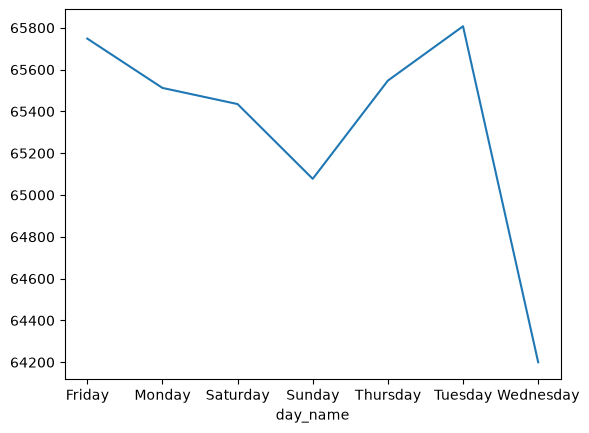

In [89]:
weekly_pattern.plot()